[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/09_naive_bayes_generative.ipynb)

# 09 · Naive Bayes & Generative Classifiers: Modeling How the Data Was Made

**Part 1 — Classical supervised learning** · Notebook 9 of 27

Logistic regression (notebook 08) models $p(y \mid x)$ directly: "given these features, how likely is each class?" There's a second, completely different way to build a classifier. Model **how each class generates its data**, $p(x \mid y)$, plus how common each class is, $p(y)$, and then flip it around with **Bayes' rule**. These are **generative** classifiers. They're often simpler to fit (frequently in closed form, by counting), they can generate new data, and they shed light on *why* logistic regression has the form it does: if the classes are Gaussian with a shared covariance, Bayes' rule produces **exactly** the logistic model.

**What you'll learn**

1. Discriminative vs. generative classifiers
2. The Bayes decision rule, and the Bayes error (the best any classifier can do)
3. Gaussian class-conditionals: fitting $\mu_k, \Sigma_k, \pi_k$ by MLE
4. **QDA**: curved (quadratic) decision boundaries
5. **LDA**: shared covariance gives straight boundaries, and the posterior is *exactly* logistic
6. **Naive Bayes**: the conditional-independence shortcut
7. A spam filter from scratch: Bernoulli and multinomial Naive Bayes, and Laplace smoothing
8. Naive Bayes is a linear classifier in disguise (CX 4240 HW3)
9. Generative vs. discriminative: who wins, and when (Ng & Jordan)
10. The generative superpower: sampling new data

*Course map: CX 4240 Lectures 8–10 (Naive Bayes, Gaussian class-conditionals, discriminative vs. generative classifiers) and HW3 (Bernoulli Naive Bayes is linear); ISYE 4600 W8 (Bayes classifier, LDA, QDA, Naive Bayes) and HW3 (Bayes classifier for spam filtering; decision boundary of a Bayesian classifier).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from scipy.stats import multivariate_normal, norm
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB, BernoulliNB, MultinomialNB
print("Ready ✓")

CLS = [C["blue"], C["red"], C["aqua"]]
def region_plot(ax, predict_proba, X, y, xlim, ylim, n=220, K=2):
    g1, g2 = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    P = predict_proba(np.column_stack([g1.ravel(), g2.ravel()]))
    if K == 2:
        ax.contourf(g1, g2, P[:, 1].reshape(g1.shape), levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.6)
        ax.contour(g1, g2, P[:, 1].reshape(g1.shape), levels=[0.5], colors=C["ink"], linewidths=2)
    else:
        ax.contourf(g1, g2, P.argmax(1).reshape(g1.shape), levels=np.arange(K + 1) - 0.5, colors=CLS[:K], alpha=0.3)
    for k in range(K):
        ax.scatter(*X[y == k].T, s=14, color=CLS[k], edgecolor="white", linewidth=0.5)
    ax.set(xlim=xlim, ylim=ylim); ax.grid(False)

Setup complete ✓


Ready ✓


---
## 1. Discriminative vs. generative

CX 4240 Lecture 10 frames the split like this. Both kinds of classifier end up computing the posterior $p(y \mid x)$ and predicting the most probable class. They differ in how they get there:

| | **Discriminative** (logistic regression, SVM, neural nets) | **Generative** (Naive Bayes, LDA, QDA) |
|---|---|---|
| Models | $p(y \mid x)$ directly | $p(x \mid y)$ and $p(y)$ |
| Then | done | Bayes' rule: $p(y\mid x) = \dfrac{p(x\mid y)\,p(y)}{\sum_{y'} p(x\mid y')\,p(y')}$ |
| Question it answers | "where's the boundary?" | "what does each class look like?" |
| Fitting | usually iterative (gradient descent) | often closed form (averages, counts) |
| Can generate new $x$? | no | yes |
| Handles missing features? | awkwardly | naturally (marginalize them out) |

An analogy: to tell cats from dogs, a discriminative model learns "pointy ears and whiskers → cat." A generative model learns "here's what cats look like; here's what dogs look like," and classifies a new animal by asking which description fits it better.

---
## 2. The Bayes decision rule and the Bayes error

Suppose for a moment we **knew** the true class-conditional distributions and priors. ISYE 4600 (W8) gives the rule: compute each class's posterior $q_k(x) = p(y = k \mid x)$ and predict the largest. For two classes, equivalently, look at the **log-likelihood ratio**

$$h(x) = \ln\frac{q_1(x)}{q_0(x)} = \ln\frac{p(x \mid y=1)}{p(x\mid y=0)} + \ln\frac{p(y=1)}{p(y=0)} \quad\text{and predict 1 if } h(x) > 0$$

The boundary is where the posteriors tie. Note the second term: a **prior** that favors one class shifts the boundary toward the *other* class, so more of the space is claimed by the common class.

This rule is optimal: no classifier can have a lower error rate. Its error, the **Bayes error**, is the classification analogue of notebook 06's noise floor. It's the overlap that remains between the classes even with perfect knowledge.

🎚️ **Two 1-D Gaussian classes.** Move them apart, change their widths and the prior. The shaded area is the Bayes error: the probability mass that lands on the wrong side of the optimal boundary.

In [2]:
def plot_bayes_1d(mu1=2.0, sd0=1.0, sd1=1.0, prior1=0.5):
    xs = np.linspace(-5, 8, 1000)
    j0 = (1 - prior1) * norm.pdf(xs, 0, sd0); j1 = prior1 * norm.pdf(xs, mu1, sd1)    # joint p(x, y)
    pred1 = j1 > j0
    err = np.trapezoid(np.where(pred1, j0, j1), xs)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[1.6, 1]))
    ax1.plot(xs, j0, color=C["blue"], lw=2, label="p(x, y=0) = p(x|y=0) p(y=0)")
    ax1.plot(xs, j1, color=C["red"], lw=2, label="p(x, y=1) = p(x|y=1) p(y=1)")
    ax1.fill_between(xs, 0, np.where(pred1, j0, j1), color=C["ink"], alpha=0.25, label=f"Bayes error = {err:.3f}")
    for b in xs[1:][np.diff(pred1.astype(int)) != 0]:
        ax1.axvline(b, color=C["ink"], ls="--", lw=1.5); ax2.axvline(b, color=C["ink"], ls="--", lw=1.5)
    ax1.set(ylabel="density", title="Predict whichever joint density is higher"); ax1.legend(fontsize=9, loc="upper right")
    post = j1 / (j0 + j1 + 1e-300)
    ax2.plot(xs, post, color=C["violet"], lw=2.5); ax2.axhline(0.5, color=C["muted"], lw=0.8)
    ax2.set(xlabel="x", ylabel="P(y=1 | x)", ylim=(-0.05, 1.05))
    fig.tight_layout(); plt.show()

interact(plot_bayes_1d, mu1=FloatSlider(value=2.0, min=0, max=6, step=0.1, description="class-1 mean"),
         sd0=FloatSlider(value=1.0, min=0.3, max=2.5, step=0.1, description="class-0 sd"),
         sd1=FloatSlider(value=1.0, min=0.3, max=2.5, step=0.1, description="class-1 sd"),
         prior1=FloatSlider(value=0.5, min=0.05, max=0.95, step=0.05, description="P(y=1)"));

Things to try:
- Make the widths **different** (say 0.5 and 2.0). Two boundaries appear: the wide class wins on *both* sides of the narrow one. A threshold on $x$ can't do that; it's a first hint of why unequal covariances give curved boundaries (section 4).
- Set the prior to 0.9: the boundary slides toward class 0, and the posterior curve shifts. Rare classes need more evidence.

Real data never comes with known distributions, so generative classifiers **estimate** $p(x\mid y)$ and $p(y)$ from training data and then plug them into this rule.

---
## 3. Gaussian class-conditionals: fitting by MLE

The most common choice is a Gaussian per class: $p(x \mid y = k) = \mathcal{N}(x;\, \mu_k, \Sigma_k)$, with prior $p(y = k) = \pi_k$. The parameters are $\theta = \{\pi_k, \mu_k, \Sigma_k\}$. Maximizing the joint log-likelihood $\sum_i \log p(x^i, y^i)$ (CX 4240 Lectures 8–9) splits into separate, easy problems, and every answer is the obvious one:

$$\hat\pi_k = \frac{N_k}{N}, \qquad \hat\mu_k = \frac{1}{N_k}\sum_{i:\,y^i = k} x^i, \qquad \hat\Sigma_k = \frac{1}{N_k}\sum_{i:\,y^i = k}(x^i - \hat\mu_k)(x^i - \hat\mu_k)^\top$$

- **Priors:** the fraction of training examples in each class. (Derived with a Lagrange multiplier for the constraint $\sum_k \pi_k = 1$, notebook 03's tool.)
- **Means:** the average of each class's points.
- **Covariances:** each class's sample covariance.

No gradient descent, no iterations: training is a single pass of averaging. Let's write it:

In [3]:
class GaussianClassifier:
    """Gaussian class-conditionals fit by MLE.  shared=True → LDA, diagonal=True → Gaussian Naive Bayes, neither → QDA."""
    def __init__(self, shared=False, diagonal=False):
        self.shared, self.diagonal = shared, diagonal
    def fit(self, X, y):
        self.classes = np.unique(y); K, d = len(self.classes), X.shape[1]
        self.pi = np.array([np.mean(y == k) for k in self.classes])
        self.mu = np.array([X[y == k].mean(0) for k in self.classes])
        covs = [np.cov(X[y == k].T, bias=True) for k in self.classes]
        if self.shared:                               # pooled covariance, weighted by class size
            S = sum(p_ * c for p_, c in zip(self.pi, covs)); covs = [S] * K
        if self.diagonal:
            covs = [np.diag(np.diag(c)) for c in covs]
        self.cov = np.array(covs)
        return self
    def log_joint(self, X):                           # log p(x, y=k) for every k
        return np.column_stack([multivariate_normal(self.mu[k], self.cov[k], allow_singular=True).logpdf(X) + np.log(self.pi[k])
                                for k in range(len(self.classes))])
    def predict_proba(self, X):
        L = self.log_joint(X); L -= L.max(1, keepdims=True)       # normalize in log space for stability
        P = np.exp(L); return P / P.sum(1, keepdims=True)
    def predict(self, X):
        return self.classes[self.log_joint(X).argmax(1)]

# Two classes with different covariances
r_ = np.random.default_rng(0)
X0 = r_.multivariate_normal([-1, 0], [[1.0, 0.6], [0.6, 1.0]], 150)
X1 = r_.multivariate_normal([1.5, 0.5], [[0.4, -0.3], [-0.3, 1.6]], 150)
Xg = np.vstack([X0, X1]); yg = np.r_[np.zeros(150, int), np.ones(150, int)]

qda = GaussianClassifier().fit(Xg, yg)
print("π̂ =", qda.pi.round(3)); print("μ̂ =\n", qda.mu.round(3)); print("Σ̂₁ =\n", qda.cov[1].round(3))
skq = QuadraticDiscriminantAnalysis(store_covariance=True, reg_param=0).fit(Xg, yg)
print("\nmax |our posterior − sklearn QDA posterior| =", np.abs(qda.predict_proba(Xg) - skq.predict_proba(Xg)).max().round(5),
      "  (sklearn divides the covariance by N_k − 1 instead of N_k; that's the whole difference)")

π̂ = [0.5 0.5]
μ̂ =
 [[-0.895  0.188]
 [ 1.494  0.491]]
Σ̂₁ =
 [[ 0.403 -0.36 ]
 [-0.36   1.542]]

max |our posterior − sklearn QDA posterior| = 0.00164   (sklearn divides the covariance by N_k − 1 instead of N_k; that's the whole difference)


---
## 4. QDA: curved decision boundaries

With a separate covariance per class, set the two log-joint densities equal to find the boundary (CX 4240 Lecture 10):

$$\log\pi_1 - \tfrac12\log|\Sigma_1| - \tfrac12(x - \mu_1)^\top\Sigma_1^{-1}(x - \mu_1) = \log\pi_0 - \tfrac12\log|\Sigma_0| - \tfrac12(x-\mu_0)^\top\Sigma_0^{-1}(x-\mu_0)$$

Expanding, the $x^\top\Sigma_k^{-1}x$ terms **don't cancel** (the $\Sigma$'s differ), leaving

$$x^\top\big(\Sigma_1^{-1} - \Sigma_0^{-1}\big)x \;-\; 2\big(\mu_1^\top\Sigma_1^{-1} - \mu_0^\top\Sigma_0^{-1}\big)x \;+\; \text{const} = 0$$

a **quadratic** equation in $x$: hence **Quadratic Discriminant Analysis**. In 2-D the boundary is a conic section: an ellipse, a parabola, or a hyperbola, depending on the two covariances.

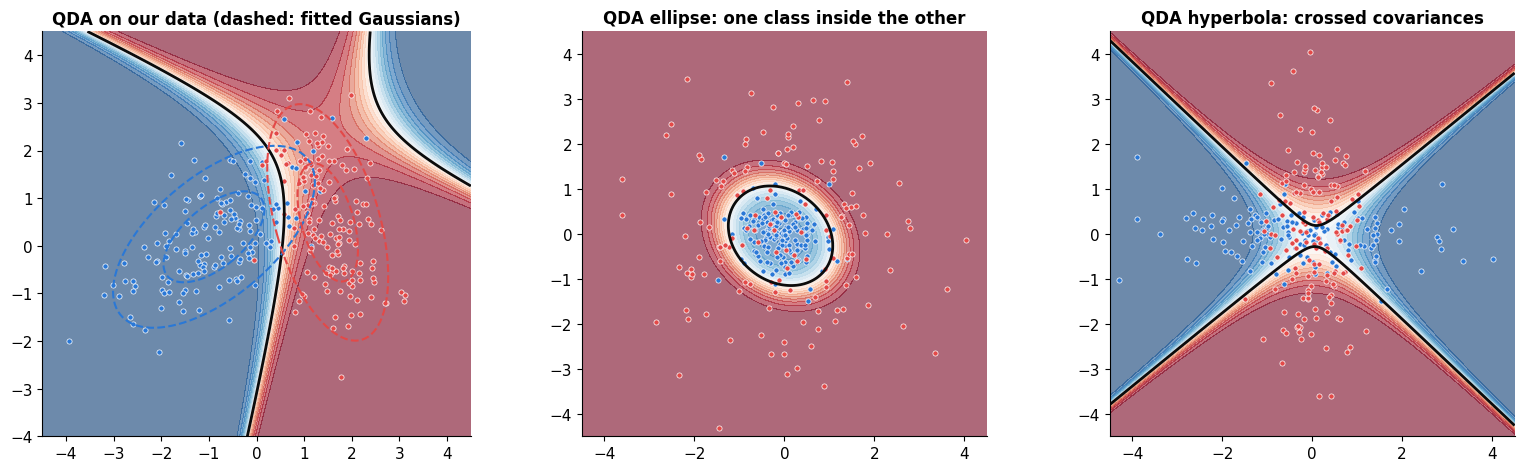

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
region_plot(axes[0], qda.predict_proba, Xg, yg, (-4.5, 4.5), (-4, 4.5))
for k, col in enumerate([C["blue"], C["red"]]):                        # 1σ and 2σ ellipses of each fitted Gaussian
    vals, vecs = np.linalg.eigh(qda.cov[k]); t = np.linspace(0, 2 * np.pi, 100)
    for s in [1, 2]:
        E = qda.mu[k][:, None] + vecs @ np.diag(s * np.sqrt(vals)) @ np.vstack([np.cos(t), np.sin(t)])
        axes[0].plot(*E, color=col, lw=1.5, ls="--")
axes[0].set(title="QDA on our data (dashed: fitted Gaussians)", aspect="equal")

shapes = [("ellipse: one class inside the other", [0, 0], np.eye(2) * 0.3, [0, 0], np.eye(2) * 2.5),
          ("hyperbola: crossed covariances", [0, 0], np.array([[2.5, 0], [0, 0.3]]), [0, 0], np.array([[0.3, 0], [0, 2.5]]))]
for ax, (name, m0, S0, m1, S1) in zip(axes[1:], shapes):
    r2 = np.random.default_rng(1)
    A = np.vstack([r2.multivariate_normal(m0, S0, 150), r2.multivariate_normal(m1, S1, 150)])
    b = np.r_[np.zeros(150, int), np.ones(150, int)]
    region_plot(ax, GaussianClassifier().fit(A, b).predict_proba, A, b, (-4.5, 4.5), (-4.5, 4.5))
    ax.set(title=f"QDA {name}", aspect="equal")
fig.tight_layout(); plt.show()

---
## 5. LDA: a shared covariance gives straight boundaries

Now assume all classes share **one** covariance matrix $\Sigma$ (estimated by pooling the classes). In the boundary equation, the $x^\top\Sigma^{-1}x$ terms now appear on both sides and **cancel**. What's left is linear in $x$ (ISYE 4600 W8):

$$\underbrace{(\mu_1 - \mu_0)^\top\Sigma^{-1}}_{w^\top}\,x \;+\; \underbrace{\tfrac12\big(\mu_0^\top\Sigma^{-1}\mu_0 - \mu_1^\top\Sigma^{-1}\mu_1\big) + \log\tfrac{\pi_1}{\pi_0}}_{b} = 0$$

That's **Linear Discriminant Analysis**. Look at the direction $w = \Sigma^{-1}(\mu_1 - \mu_0)$: not simply the line between the means, but that line "corrected" by the covariance, so it accounts for which directions are noisy.

### The deeper connection: the LDA posterior is exactly logistic

Here's the payoff from CX 4240 Lecture 10. Write the posterior for class 1 with Bayes' rule and divide top and bottom by the numerator:

$$p(y=1\mid x) = \frac{\pi_1\mathcal{N}(x;\mu_1,\Sigma)}{\pi_0\mathcal{N}(x;\mu_0,\Sigma) + \pi_1\mathcal{N}(x;\mu_1,\Sigma)} = \frac{1}{1 + \exp\!\Big(-\ln\frac{\pi_1\mathcal{N}(x;\mu_1,\Sigma)}{\pi_0\mathcal{N}(x;\mu_0,\Sigma)}\Big)} = \frac{1}{1 + e^{-(w^\top x + b)}} = \sigma(w^\top x + b)$$

using exactly the $w, b$ above (the log-ratio of two Gaussians with equal covariance is linear). **Gaussian classes with a shared covariance imply the logistic-regression form.** That's one principled reason the logistic model is a sensible default. Let's verify numerically:

w = [1.801 0.591]   b = -0.677
max |Bayes-rule posterior − σ(wᵀx + b)| = 3.3306690738754696e-16

LDA (generative) weights:          w = [1.801 0.591]  b = -0.677
Logistic regression (discriminative): [1.768 0.619]  b = -0.718


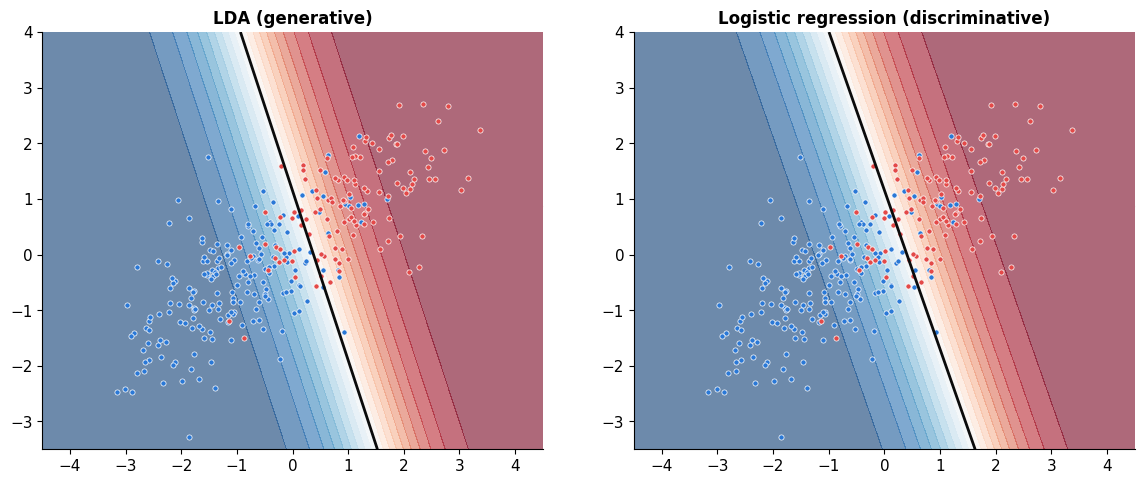

In [5]:
r_ = np.random.default_rng(3)
S_shared = np.array([[1.0, 0.5], [0.5, 0.8]])
XL = np.vstack([r_.multivariate_normal([-1, -0.5], S_shared, 200), r_.multivariate_normal([1.2, 0.8], S_shared, 120)])
yL = np.r_[np.zeros(200, int), np.ones(120, int)]
lda = GaussianClassifier(shared=True).fit(XL, yL)
Si = np.linalg.inv(lda.cov[0])
w = Si @ (lda.mu[1] - lda.mu[0])
b = 0.5 * (lda.mu[0] @ Si @ lda.mu[0] - lda.mu[1] @ Si @ lda.mu[1]) + np.log(lda.pi[1] / lda.pi[0])

post_bayes = lda.predict_proba(XL)[:, 1]
post_logistic_form = 1 / (1 + np.exp(-(XL @ w + b)))
print("w =", w.round(3), "  b =", round(b, 3))
print("max |Bayes-rule posterior − σ(wᵀx + b)| =", np.abs(post_bayes - post_logistic_form).max())

lr = LogisticRegression(C=1e6).fit(XL, yL)
print("\nLDA (generative) weights:          w =", w.round(3), " b =", round(b, 3))
print("Logistic regression (discriminative):", lr.coef_[0].round(3), " b =", round(lr.intercept_[0], 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
region_plot(axes[0], lda.predict_proba, XL, yL, (-4.5, 4.5), (-3.5, 4)); axes[0].set(title="LDA (generative)", aspect="equal")
region_plot(axes[1], lr.predict_proba, XL, yL, (-4.5, 4.5), (-3.5, 4)); axes[1].set(title="Logistic regression (discriminative)", aspect="equal")
fig.tight_layout(); plt.show()

The Bayes-rule posterior and the logistic formula agree to machine precision. And the two **fitted** models land on similar, but not identical, lines: same functional form, different estimation. LDA estimates $\mu$'s and $\Sigma$ (using the assumption that the data is Gaussian); logistic regression fits $w, b$ directly by maximizing the conditional likelihood (assuming nothing about how $x$ is distributed). Section 9 asks which approach wins.

> 🤔 **Question: Is this the same LDA as "Fisher's linear discriminant" used for dimensionality reduction?**
>
> Closely related. Fisher asked a different question: which 1-D projection direction best separates the class means relative to the within-class spread? The answer is the same direction $w \propto \Sigma^{-1}(\mu_1 - \mu_0)$. With $K$ classes, LDA gives up to $K - 1$ such directions, so it's also used to project data down for visualization, a supervised cousin of PCA (notebook 16).

---
## 6. Naive Bayes: the conditional-independence shortcut

A full covariance matrix in $d$ dimensions has $d(d+1)/2$ parameters per class. With $d = 10{,}000$ word features that's 50 million numbers per class: impossible to estimate. **Naive Bayes** makes a drastic simplification: assume the features are **conditionally independent given the class**:

$$p(x \mid y) = \prod_{j=1}^d p(x_j \mid y)$$

Each feature gets its own little 1-D model per class. For Gaussian features this means **diagonal** covariances. For the parameter count, CX 4240 Lecture 10 compares: Gaussian Naive Bayes needs about $4d + 1$ numbers for 2 classes ($2d$ means, $2d$ variances, 1 prior); logistic regression needs $d + 1$; full QDA needs $O(d^2)$.

"Naive" because the assumption is almost always false (word counts in an email are not independent: "Nigerian" and "prince" co-occur). The surprise is how well it works anyway. It often gets the **ranking** of classes right even when its probabilities are badly miscalibrated (the independence assumption double-counts correlated evidence, so the probabilities end up too extreme).

max |our Gaussian NB posterior − sklearn's| = 0.0


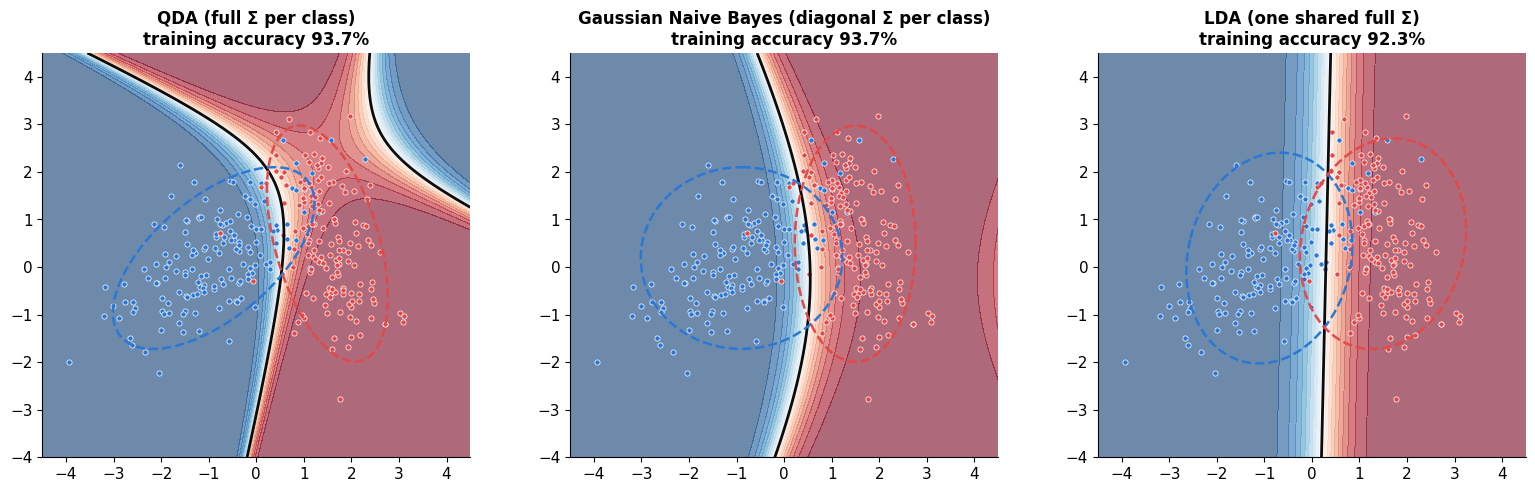

In [6]:
nb = GaussianClassifier(diagonal=True).fit(Xg, yg)
sknb = GaussianNB(var_smoothing=0).fit(Xg, yg)
print("max |our Gaussian NB posterior − sklearn's| =", np.abs(nb.predict_proba(Xg) - sknb.predict_proba(Xg)).max().round(8))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, mdl) in zip(axes, [("QDA (full Σ per class)", qda), ("Gaussian Naive Bayes (diagonal Σ per class)", nb),
                                  ("LDA (one shared full Σ)", GaussianClassifier(shared=True).fit(Xg, yg))]):
    region_plot(ax, mdl.predict_proba, Xg, yg, (-4.5, 4.5), (-4, 4.5))
    for k, col in enumerate([C["blue"], C["red"]]):
        vals, vecs = np.linalg.eigh(mdl.cov[k]); t = np.linspace(0, 2 * np.pi, 100)
        E = mdl.mu[k][:, None] + vecs @ np.diag(2 * np.sqrt(vals)) @ np.vstack([np.cos(t), np.sin(t)])
        ax.plot(*E, color=col, lw=1.8, ls="--")
    ax.set(title=f"{name}\ntraining accuracy {np.mean(mdl.predict(Xg) == yg):.1%}", aspect="equal")
fig.tight_layout(); plt.show()

The dashed ellipses show each model's picture of the classes. Naive Bayes forces them to be **axis-aligned** (no tilt, because a diagonal covariance can't represent correlation between features). LDA allows tilt but makes the two classes the same shape. QDA lets each class have its own shape. Three points on a bias–variance spectrum (notebook 06): more flexible, more parameters, more data needed.

---
## 7. A spam filter from scratch

Text is Naive Bayes' home turf. Represent each message by which words it contains. ISYE 4600's HW3 worked a tiny spam filter by hand; let's do the same with our own toy messages, then scale up.

### By hand, on six messages

In [7]:
spam = ["win a free prize now", "free money win now", "claim your free prize"]
ham = ["meeting at noon tomorrow", "can you send the notes", "lunch tomorrow at noon"]
vocab = sorted({w for m in spam + ham for w in m.split()})
def bow(msgs, binary=True):
    M = np.array([[m.split().count(w) for w in vocab] for m in msgs])
    return (M > 0).astype(int) if binary else M
Xs_, Xh_ = bow(spam), bow(ham)
print(f"vocabulary ({len(vocab)} words):", vocab)
pd.DataFrame(np.vstack([Xs_, Xh_]), columns=vocab, index=[f"spam: {m}" for m in spam] + [f"ham: {m}" for m in ham])

vocabulary (18 words): ['a', 'at', 'can', 'claim', 'free', 'lunch', 'meeting', 'money', 'noon', 'notes', 'now', 'prize', 'send', 'the', 'tomorrow', 'win', 'you', 'your']


,a,at,can,claim,free,lunch,meeting,money,noon,notes,now,prize,send,the,tomorrow,win,you,your
spam: win a free prize now,1,0,0,0,1,0,0,0,0,0,1,1,0,0,0,1,0,0
spam: free money win now,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0,0
spam: claim your free prize,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,1
ham: meeting at noon tomorrow,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0
ham: can you send the notes,0,0,1,0,0,0,0,0,0,1,0,0,1,1,0,0,1,0
ham: lunch tomorrow at noon,0,1,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0


**Bernoulli Naive Bayes** models each word as a coin flip per class: $\phi_{jk} = P(\text{word } j \text{ appears} \mid y = k)$. The MLE is just a fraction: the share of class-$k$ messages containing word $j$. Then score a new message:

$$\log p(x, y = k) = \log\pi_k + \sum_j \Big[x_j\log\phi_{jk} + (1 - x_j)\log(1 - \phi_{jk})\Big]$$

Try it on "free lunch tomorrow":

In [8]:
phi_spam_mle, phi_ham_mle = Xs_.mean(0), Xh_.mean(0)
x_new = bow(["free lunch tomorrow"])[0]
with np.errstate(divide="ignore"):
    for name, phi in [("spam", phi_spam_mle), ("ham", phi_ham_mle)]:
        lj = np.log(0.5) + np.sum(np.where(x_new == 1, np.log(phi), np.log(1 - phi)))     # log P(present) or log P(absent), per word
        print(f"log p(x, {name}) = {lj}")

log p(x, spam) = -inf
log p(x, ham) = -inf


Both are $-\infty$! "lunch" never appeared in spam, so $\hat\phi_{\text{lunch},\text{spam}} = 0$, and one zero factor kills the whole product. Likewise "free" never appeared in ham. With a real vocabulary, almost every message contains *some* word never seen in some class, so pure MLE is useless.

**Laplace (add-one) smoothing** fixes it: pretend we saw every word once more, and every word's absence once more, in each class:

$$\hat\phi_{jk} = \frac{(\#\text{ class-}k\text{ messages with word } j) + \alpha}{N_k + 2\alpha}, \qquad \alpha = 1$$

This is exactly **MAP with a Beta(α+1, α+1) prior** on each $\phi$ (notebook 02, section 10): a prior belief that no word is impossible in either class.

In [9]:
def bernoulli_nb_fit(X, y, alpha=1.0):
    classes = np.unique(y)
    log_prior = np.log(np.array([np.mean(y == k) for k in classes]))
    phi = np.array([(X[y == k].sum(0) + alpha) / ((y == k).sum() + 2 * alpha) for k in classes])
    return log_prior, phi

def bernoulli_nb_log_joint(X, log_prior, phi):
    return X @ np.log(phi).T + (1 - X) @ np.log(1 - phi).T + log_prior

Xtoy = np.vstack([Xs_, Xh_]); ytoy = np.r_[np.ones(3, int), np.zeros(3, int)]      # 1 = spam
lp, phi = bernoulli_nb_fit(Xtoy, ytoy)
lj = bernoulli_nb_log_joint(x_new[None, :], lp, phi)[0]
post_spam = 1 / (1 + np.exp(lj[0] - lj[1]))
print(f"log p(x, ham) = {lj[0]:.3f},  log p(x, spam) = {lj[1]:.3f}  →  P(spam | 'free lunch tomorrow') = {post_spam:.3f}")
sk_b = BernoulliNB(alpha=1.0).fit(Xtoy, ytoy)
print(f"scikit-learn BernoulliNB agrees: {sk_b.predict_proba(x_new[None, :])[0, 1]:.3f}")

log p(x, ham) = -10.189,  log p(x, spam) = -10.712  →  P(spam | 'free lunch tomorrow') = 0.372
scikit-learn BernoulliNB agrees: 0.372


"free" points to spam, but "lunch" and "tomorrow" point to ham, and with smoothing the model can weigh them all.

### Scaling up: a synthetic email corpus

Now a larger, synthetic corpus: 2,000 messages drawn from a vocabulary of 300 words, where some words are spam-flavored, some ham-flavored, and most are neutral. (Synthetic so that it runs anywhere without downloads; the mechanics are identical on real data.)

Bernoulli Naive Bayes test accuracy: 98.7%   (training = counting, no iterations)


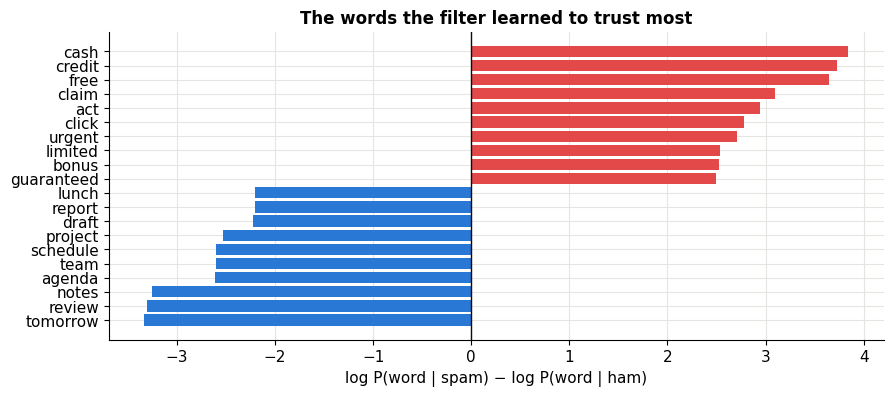

In [10]:
rng_t = np.random.default_rng(0)
V = 300
spammy = ["free", "win", "prize", "cash", "offer", "click", "urgent", "winner", "credit", "deal", "bonus", "claim", "guaranteed", "limited", "act"]
hammy = ["meeting", "lunch", "project", "tomorrow", "notes", "report", "thanks", "schedule", "team", "call", "review", "draft", "agenda", "class", "homework"]
words = spammy + hammy + [f"w{i:03d}" for i in range(V - len(spammy) - len(hammy))]
base = rng_t.uniform(0.005, 0.06, V)                         # neutral words: similar rate in both classes
p_spam_w, p_ham_w = base.copy(), base.copy()
p_spam_w[:15] = rng_t.uniform(0.15, 0.45, 15); p_ham_w[:15] = rng_t.uniform(0.005, 0.04, 15)
p_spam_w[15:30] = rng_t.uniform(0.005, 0.04, 15); p_ham_w[15:30] = rng_t.uniform(0.12, 0.40, 15)
n_msg = 2000; y_mail = (rng_t.random(n_msg) < 0.35).astype(int)          # 35% spam
X_mail = (rng_t.random((n_msg, V)) < np.where(y_mail[:, None] == 1, p_spam_w, p_ham_w)).astype(int)
tr_m, te_m = np.arange(1400), np.arange(1400, 2000)

lp, phi = bernoulli_nb_fit(X_mail[tr_m], y_mail[tr_m])
pred = bernoulli_nb_log_joint(X_mail[te_m], lp, phi).argmax(1)
print(f"Bernoulli Naive Bayes test accuracy: {np.mean(pred == y_mail[te_m]):.1%}   (training = counting, no iterations)")

log_ratio = np.log(phi[1]) - np.log(phi[0])
order = np.argsort(log_ratio)
fig, ax = plt.subplots(figsize=(10, 4))
sel = np.r_[order[:10], order[-10:]]
ax.barh([words[j] for j in sel], log_ratio[sel], color=[C["blue"]] * 10 + [C["red"]] * 10)
ax.axvline(0, color=C["ink"], lw=1)
ax.set(xlabel="log P(word | spam) − log P(word | ham)", title="The words the filter learned to trust most")
plt.show()

### Multinomial Naive Bayes

The Bernoulli model only records *whether* each word appears. The **multinomial** model (used in ISYE 4600 HW3) records *how often*: a message is a bag of word draws from a class-specific distribution over the vocabulary, $p(x\mid y=k) \propto \prod_j \theta_{jk}^{\,x_j}$ where $x_j$ is the count of word $j$. Its MLE is again a ratio of counts, $\hat\theta_{jk} = \frac{\text{count of word } j \text{ in class } k + \alpha}{\text{total words in class } k + \alpha V}$. It tends to do better for longer documents, where repetition carries information; Bernoulli tends to do better for short ones, where *absence* of a word is informative.

---
## 8. Naive Bayes is a linear classifier in disguise (CX 4240 HW3)

Look at the Bernoulli Naive Bayes log-odds:

$$\log\frac{p(y=1\mid x)}{p(y=0\mid x)} = \log\frac{\pi_1}{\pi_0} + \sum_j \Big[x_j\log\frac{\phi_{j1}}{\phi_{j0}} + (1-x_j)\log\frac{1 - \phi_{j1}}{1 - \phi_{j0}}\Big]$$

Every term is **linear in $x_j$** (because $x_j \in \{0,1\}$). Collect them:

$$= \underbrace{\sum_j \log\frac{\phi_{j1}(1 - \phi_{j0})}{\phi_{j0}(1 - \phi_{j1})}}_{\text{each is } w_j}\,x_j \;+\; \underbrace{\log\frac{\pi_1}{\pi_0} + \sum_j\log\frac{1 - \phi_{j1}}{1 - \phi_{j0}}}_{w_0} \;=\; w^\top x + w_0$$

So $p(y=1\mid x) = \sigma(w^\top x + w_0)$: **the same functional form as logistic regression.** Bernoulli Naive Bayes and logistic regression are both linear classifiers; they just choose the weights differently. Naive Bayes computes them in closed form from per-feature counts (decoupled, one feature at a time). Logistic regression optimizes them jointly (coupled). Let's confirm on the spam data:

max |NB posterior − σ(wᵀx + w0)| = 2.0539125955565396e-15
Logistic regression test accuracy: 98.5%


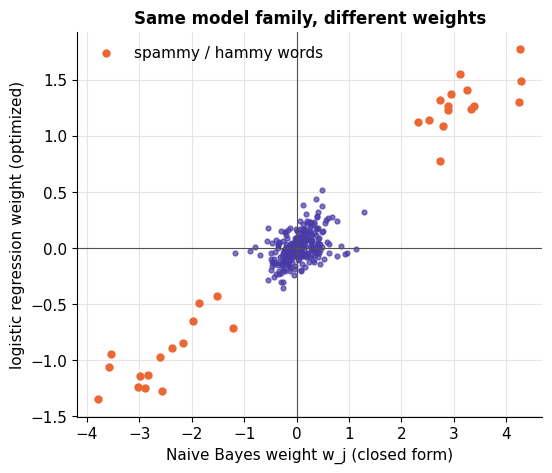

In [11]:
w_nb = np.log(phi[1] * (1 - phi[0]) / (phi[0] * (1 - phi[1])))
w0_nb = lp[1] - lp[0] + np.sum(np.log((1 - phi[1]) / (1 - phi[0])))
post_formula = 1 / (1 + np.exp(-(X_mail[te_m] @ w_nb + w0_nb)))
lj = bernoulli_nb_log_joint(X_mail[te_m], lp, phi)
post_nb = 1 / (1 + np.exp(lj[:, 0] - lj[:, 1]))
print("max |NB posterior − σ(wᵀx + w0)| =", np.abs(post_formula - post_nb).max())

lr_mail = LogisticRegression(C=0.5, max_iter=5000).fit(X_mail[tr_m], y_mail[tr_m])
print(f"Logistic regression test accuracy: {lr_mail.score(X_mail[te_m], y_mail[te_m]):.1%}")
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(w_nb, lr_mail.coef_[0], s=12, color=C["violet"], alpha=0.7)
ax.scatter(w_nb[:30], lr_mail.coef_[0][:30], s=25, color=C["orange"], label="spammy / hammy words")
ax.axhline(0, color=C["muted"], lw=0.8); ax.axvline(0, color=C["muted"], lw=0.8)
ax.set(xlabel="Naive Bayes weight w_j (closed form)", ylabel="logistic regression weight (optimized)", title="Same model family, different weights"); ax.legend()
plt.show()

The weights line up: both models agree on which words matter and in which direction. Naive Bayes' weights are more extreme for the informative words. That's the "double counting" of correlated evidence in action, and why Naive Bayes probabilities tend to be overconfident.

---
## 9. Generative vs. discriminative: who wins, and when?

A famous paper by Ng & Jordan (2001), cited in CX 4240 Lecture 10, compared Naive Bayes and logistic regression and proposed a pattern:

- **Asymptotically, logistic regression wins** whenever Naive Bayes' assumptions are wrong: it has lower **bias** (it doesn't assume independence), so with enough data it reaches a lower error.
- **With very little data, Naive Bayes can win**: its estimates are decoupled per-feature averages, so it approaches *its* best performance with far fewer examples (roughly $O(\log d)$ vs. $O(d)$).

Let's test both claims instead of taking them on faith. The data: 30 continuous features, two Gaussian classes. In one version the features are independent within each class (Naive Bayes' assumption is **true**); in the other, features come in correlated blocks of 5 (the assumption is **false**). We trace test error against training-set size for Gaussian Naive Bayes and (default-regularized) logistic regression:

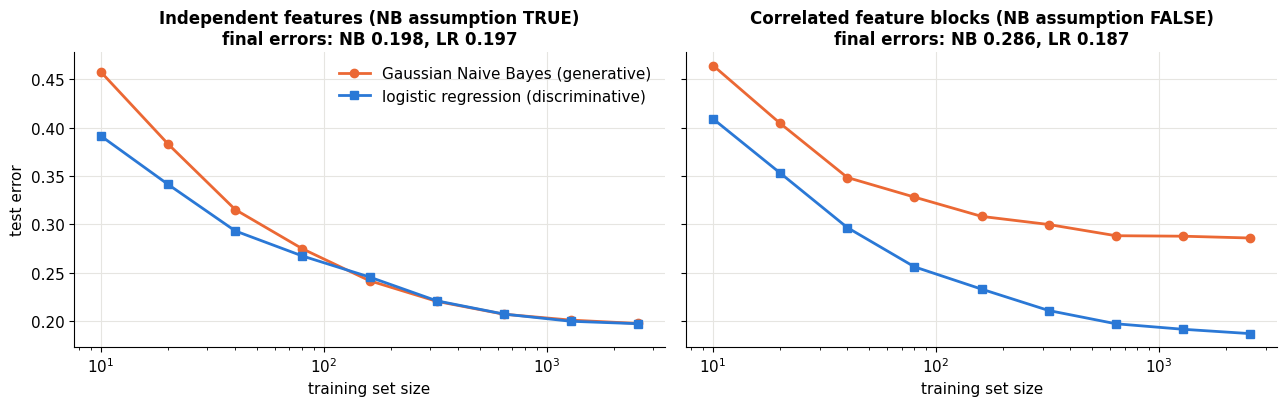

In [12]:
def gaussian_task(rho, d=30, scale=0.4, seed_mu=0):
    S = np.eye(d)
    for b0 in range(0, d, 5): S[b0:b0 + 5, b0:b0 + 5] = rho
    np.fill_diagonal(S, 1.0)
    dmu = np.abs(np.random.default_rng(seed_mu).normal(0, scale, d))
    def make(n, seed):
        rr = np.random.default_rng(seed); y_ = (rr.random(n) < 0.5).astype(int)
        return rr.multivariate_normal(np.zeros(d), S, n) + y_[:, None] * dmu, y_
    return make

def learning_curves(make, sizes, reps=30):
    Xp, yp = make(12000, 1); Xt, yt = make(5000, 2); rr = np.random.default_rng(0)
    nb_err, lr_err = [], []
    for n_ in sizes:
        a, b = [], []
        for _ in range(reps):
            idx = rr.choice(len(yp), n_, replace=False)
            if len(np.unique(yp[idx])) < 2: continue
            a.append(1 - GaussianNB().fit(Xp[idx], yp[idx]).score(Xt, yt))
            b.append(1 - LogisticRegression(max_iter=3000).fit(Xp[idx], yp[idx]).score(Xt, yt))
        nb_err.append(np.mean(a)); lr_err.append(np.mean(b))
    return np.array(nb_err), np.array(lr_err)

sizes = [10, 20, 40, 80, 160, 320, 640, 1280, 2560]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (rho, title) in zip(axes, [(0.0, "Independent features (NB assumption TRUE)"), (0.6, "Correlated feature blocks (NB assumption FALSE)")]):
    nb_e, lr_e = learning_curves(gaussian_task(rho), sizes)
    ax.plot(sizes, nb_e, "-o", color=C["orange"], label="Gaussian Naive Bayes (generative)")
    ax.plot(sizes, lr_e, "-s", color=C["blue"], label="logistic regression (discriminative)")
    ax.set(xscale="log", xlabel="training set size", title=f"{title}\nfinal errors: NB {nb_e[-1]:.3f}, LR {lr_e[-1]:.3f}")
axes[0].set_ylabel("test error"); axes[0].legend()
fig.tight_layout(); plt.show()

What the experiment shows:

- **The asymptotic claim holds, and it's large.** With independent features (left), both models converge to the same error: Naive Bayes is the correct model, so nothing is lost. With correlated features (right), Naive Bayes **plateaus far above** logistic regression and never catches up, no matter how much data it gets. It treats five correlated features as five independent pieces of evidence and points its boundary in the wrong direction (section 6's axis-aligned ellipses).
- **The small-sample advantage is not guaranteed.** Here, regularized logistic regression is never worse, even at 10 examples. Ng & Jordan compared against *unregularized* logistic regression, which overfits badly with tiny samples; modern defaults regularize, which removes most of that gap. Naive Bayes' speed advantage shows up most with many sparse, discrete features (like text) and very few examples.

The general lesson for any generative vs. discriminative pair is still notebook 06's bias–variance tradeoff: **strong assumptions (generative) cost you when they're wrong, and buy you stability when data is scarce; flexible models (discriminative) need more data but go further.** Which effect dominates is an empirical question, so test it, as we just did.

---
## 10. The generative superpower: sampling new data

A discriminative model can't tell you what a "3" looks like; it only knows where the boundary between 3s and 8s is. A generative model is a full description of each class, so you can **sample** from it. Fit Bernoulli Naive Bayes to binarized handwritten digits (notebook 08's dataset) and look inside:

Bernoulli Naive Bayes on binarized digits: test accuracy 88.7%


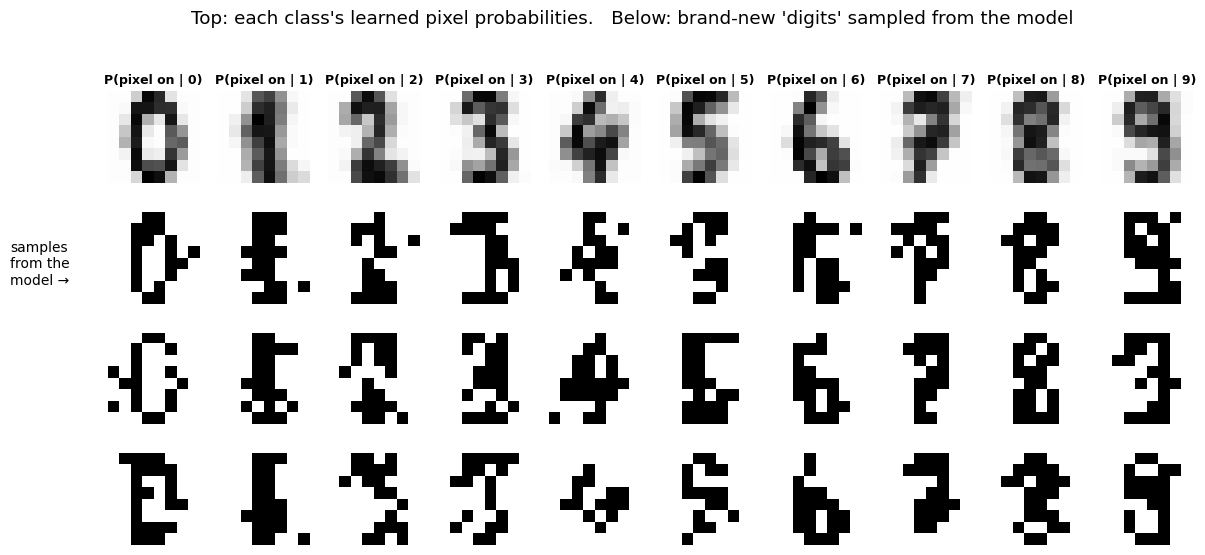

In [13]:
dg = load_digits(); Xd = (dg.data > 7).astype(int); yd = dg.target
perm = np.random.default_rng(0).permutation(len(yd)); trd, ted = perm[:1300], perm[1300:]
lp_d, phi_d = bernoulli_nb_fit(Xd[trd], yd[trd])
acc_d = np.mean(bernoulli_nb_log_joint(Xd[ted], lp_d, phi_d).argmax(1) == yd[ted])
print(f"Bernoulli Naive Bayes on binarized digits: test accuracy {acc_d:.1%}")

rs = np.random.default_rng(5)
fig, axes = plt.subplots(4, 10, figsize=(14, 6))
for k in range(10):
    axes[0, k].imshow(phi_d[k].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); axes[0, k].set_title(f"P(pixel on | {k})", fontsize=9)
    for r in range(1, 4):
        axes[r, k].imshow((rs.random(64) < phi_d[k]).reshape(8, 8), cmap="gray_r")
for ax in axes.ravel(): ax.axis("off")
axes[1, 0].text(-9, 4, "samples\nfrom the\nmodel →", fontsize=10, va="center")
fig.suptitle("Top: each class's learned pixel probabilities.   Below: brand-new 'digits' sampled from the model", y=1.01)
plt.show()

The top row is the model's entire knowledge: a probability per pixel per class (blurry averages of each digit). The samples below are new images the model generates by flipping each pixel's coin independently. They're recognizably digit-shaped but **speckled and broken**, because the independence assumption ignores that neighboring pixels go together: real strokes are continuous, but independent coins can't produce continuity. Same 8×8 classifier accuracy story: it works (around 85–90%), yet clearly doesn't "understand" digits.

Better generative models capture the dependencies. Notebook 15 (Gaussian mixtures) and notebook 23 (variational autoencoders) are generative models of increasing power, and modern image generators are this same idea taken very far.

> 🤔 **Question: Can a generative classifier be used without labels?**
>
> Yes, and that's a big deal. If labels are missing, $p(x) = \sum_k p(x\mid y=k)\,p(y=k)$ is a **mixture** of the class-conditional distributions, and you can still fit it by maximum likelihood, treating the label as a hidden variable. With Gaussian class-conditionals, that's the **Gaussian mixture model**, fit with the EM algorithm: notebook 15. CX 4240 Lecture 10 ends on exactly this connection.

---
## 11. Summary

| Model | $p(x\mid y)$ | Boundary | Parameters (2 classes, $d$ features) | Fit by |
|---|---|---|---|---|
| QDA | full Gaussian per class | quadratic | $O(d^2)$ | means & covariances |
| LDA | full Gaussian, shared $\Sigma$ | linear | $O(d^2)$ (one $\Sigma$) | means & pooled covariance |
| Gaussian NB | diagonal Gaussian per class | quadratic (axis-aligned) | $4d + 1$ | per-feature means & variances |
| Bernoulli / multinomial NB | independent coins / word counts | linear | $O(d)$ | counts + Laplace smoothing |
| *Logistic regression* | *(not modeled)* | *linear* | $d + 1$ | *gradient descent / Newton* |

Key ideas: the **Bayes rule** picks the class with the highest posterior and is optimal if the model is right; the **Bayes error** is the irreducible floor; generative models are fit by **counting and averaging**; **shared covariance ⇒ linear boundary ⇒ exactly the logistic form**; **Naive Bayes** trades correctness for scalability and is a linear classifier in disguise; **Laplace smoothing** = MAP with a Beta prior; when its assumptions are wrong, a generative model **plateaus at a worse error** that more data can't fix.

### ✏️ Exercises

1. Derive $\hat\pi_k = N_k/N$ by maximizing $\sum_k N_k\log\pi_k$ subject to $\sum_k\pi_k = 1$ with a Lagrange multiplier.
2. Show that for two 1-D Gaussian classes with equal variance and equal priors, the Bayes boundary is the midpoint of the means. Where does it move with unequal priors?
3. Implement **multinomial** Naive Bayes on the synthetic corpus (generate word *counts* instead of 0/1) and compare with Bernoulli.
4. Show that Gaussian Naive Bayes with a **shared** diagonal covariance is also a linear classifier, and write out its weights.
5. On the digits data, compare QDA, LDA, Gaussian NB and logistic regression. QDA will struggle: why? *(Hint: count the parameters in a 64×64 covariance per class vs. ~130 training images per class. Try `reg_param` in sklearn's QDA.)*
6. Calibration check: on the correlated-features task, histogram Naive Bayes's predicted probabilities vs. logistic regression's. Which are more extreme, and why? *(Hint: correlated evidence gets counted several times.)*
7. Redo section 9 with `LogisticRegression(C=1e6)` (essentially unregularized). Does Naive Bayes win at small sample sizes now?

### References

- CX 4240 Lecture 8 (Naive Bayes classification, MLE of Gaussian class-conditionals), Lecture 9 (Naive Bayes classifier), Lecture 10 (discriminative vs. generative; posterior of Gaussian NB is logistic; quadratic vs. linear boundaries); HW3 (Bernoulli NB as a linear model).
- ISYE 4600 W8 (Bayes decision rule, LDA, QDA, Naive Bayes) and HW3 (Bayes classifier for spam filtering; decision boundary of a Bayesian classifier).
- A. Ng & M. Jordan, *On Discriminative vs. Generative Classifiers: A comparison of logistic regression and naive Bayes*, NeurIPS (2001).
- C. Bishop, *Pattern Recognition and Machine Learning*, Section 4.2 (probabilistic generative models).
- T. Hastie, R. Tibshirani & J. Friedman, *The Elements of Statistical Learning*, Sections 4.3 (LDA/QDA) and 6.6.3 (Naive Bayes).
- C. Manning, P. Raghavan & H. Schütze, *Introduction to Information Retrieval*, Chapter 13 (text classification and Naive Bayes).

**Next → [10 · KNN & Classifier Evaluation](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/10_knn_evaluation.ipynb)**